# Lesson 7 — Evaluation and thresholds: grading a model honestly

Lesson 7 — Evaluation and thresholds: grading a model honestly
==============================================================

GURU NOTE
---------
A trained model gives a probability. A firewall must give a DECISION. This lesson
covers both halves your repo's eval.py handles:

  A. HONEST GRADING — never grade on data the model trained on (it may have
     memorized it). Hold out a validation set. Then measure:
       precision  = of what we flagged, how much was real?
       recall/TPR = of real attacks, how many did we catch?
       TNR        = of benign traffic, how much did we correctly leave alone?
       AUC        = probability a random attack outranks a random benign request.

  B. CHOOSING THRESHOLDS — the model outputs p in [0,1]; we pick a cutoff. Your
     repo picks TWO: a high `prevent` cutoff (block — demands TNR >= 0.995) and a
     lower `detect` cutoff (just log). We reproduce that calibration here.

Every function here has a twin in eval.py. After this lesson, open eval.py and
you'll recognize all of it.

Run me:  python lessons/lesson_07_evaluation_and_thresholds.py

## Setup

These notebooks *import* the real code from `lessons/*.py` — one source of truth, no forked copies. This cell finds that folder.

In [1]:
import sys, pathlib
for base in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
    if (base / 'lessons' / '_util.py').exists():
        sys.path.insert(0, str(base / 'lessons'))
        print('lessons on path:', base / 'lessons'); break
else:
    raise RuntimeError('Open this notebook inside the xorguard-ml-course folder.')

lessons on path: /Users/anil/Documents/developer/vscodeworkspaces/xordev/xorguard-ml-course/lessons


## The key code (shown live from the source file)

Read it, then copy any function into a new cell and tweak it — the originals live in `lessons/lesson_07_evaluation_and_thresholds.py`.

In [2]:
import inspect
from lesson_07_evaluation_and_thresholds import at_threshold, roc_auc, calibrate_for_tnr
for fn in (at_threshold, roc_auc, calibrate_for_tnr):
    print(inspect.getsource(fn)); print('-' * 72)

def at_threshold(y, p, t):
    """Confusion-matrix stats at cutoff t. Mirrors eval.at_threshold."""
    pred = p >= t
    truth = y >= 0.5
    tp = float(np.sum(pred & truth)); fp = float(np.sum(pred & ~truth))
    fn = float(np.sum(~pred & truth)); tn = float(np.sum(~pred & ~truth))
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    rec = tp / (tp + fn) if (tp + fn) else 0.0
    tnr = tn / (tn + fp) if (tn + fp) else 0.0
    return {"t": t, "precision": prec, "recall": rec, "tnr": tnr, "fpr": 1 - tnr}

------------------------------------------------------------------------
def roc_auc(y, p):
    """AUC = P(a random attack scores above a random benign request).

    This is the Wilcoxon-Mann-Whitney formulation — count winning pairs, ties
    half. Identical idea to eval.roc_auc. 1.0 = perfect ranking, 0.5 = coin flip.
    """
    pos = p[y >= 0.5]
    neg = p[y < 0.5]
    if len(pos) == 0 or len(neg) == 0:
        return float("nan")
    wins = 0.0
    for pi in pos:
        wins +=

## A picture

A real plot (matplotlib) in place of the terminal's ASCII. Re-run after changing inputs to build intuition.

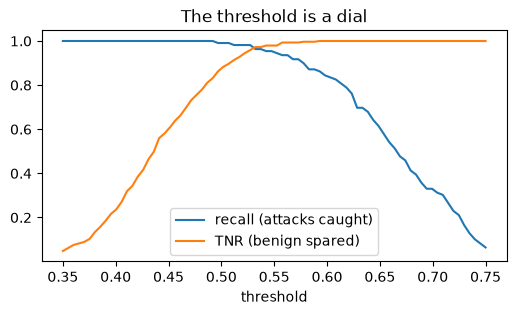

In [3]:
import numpy as np, matplotlib.pyplot as plt
from lesson_02_score_and_sigmoid import sigmoid
from lesson_06_class_imbalance import fit
from lesson_07_evaluation_and_thresholds import make_noisy, split, at_threshold
X, y = make_noisy(); Xtr, ytr, Xva, yva = split(X, y)
w = fit(Xtr, ytr, balance=True, fp_weight=1.0); p = sigmoid(Xva @ w)
ts = np.linspace(0.35, 0.75, 80)
rec = [at_threshold(yva, p, t)['recall'] for t in ts]
tnr = [at_threshold(yva, p, t)['tnr'] for t in ts]
plt.figure(figsize=(6, 3))
plt.plot(ts, rec, label='recall (attacks caught)')
plt.plot(ts, tnr, label='TNR (benign spared)')
plt.xlabel('threshold'); plt.title('The threshold is a dial'); plt.legend(); plt.show()

## Run the full narrated lesson

This executes the same walkthrough as `python lessons/lesson_07_evaluation_and_thresholds.py`, printing each step with its result.

In [4]:
from lesson_07_evaluation_and_thresholds import main
main()


════════════════════════════════════
Lesson 7 — Evaluation and thresholds
════════════════════════════════════

▸ Rule 1: split. Train on 80%, GRADE on the held-out 20%.
    train rows = 1600,  validation rows = 400
    The model never sees validation rows during training. That's the
    only way to estimate how it does on traffic it hasn't met.

▸ Rule 2: report the metrics that matter (at the default 0.5 cutoff).
    precision = 74.0%  (of alarms, how many were real)
    recall    = 99.1%  (of attacks, how many we caught)
    TNR       = 86.9%  (of benign, how many we spared)
    AUC       = 0.9963  (ranking quality, cutoff-free)
    AUC is special: it grades the model's RANKING, independent of where
    you put the cutoff. 1.0 = every attack scores above every benign req.

▸ Notice: the model's probabilities are COMPRESSED, not spread over 0..1.
    p ranges from 0.31 to 0.78 — attacks don't reach
    0.99, benign don't reach 0.01. This is normal, and it's exactly WHY we
    don't 

## Exercises

Try these in new cells below. Worked answers are in `solutions/lesson_07_solution.py`.

```
1. Retrain with fp_weight=1 and fp_weight=6, and for each print the AUC on the
   validation set. Does fp_weight change the AUC much? (Surprise: AUC is about
   RANKING, which the cutoff/cost doesn't change nearly as much as you'd think.)

2. Write precision_at_recall(y, p, target_recall): find the highest-precision
   threshold that still catches at least target_recall of attacks. This is how
   a team asks "how clean can we be while still catching 90% of attacks?"

3. Lower the target_tnr to 0.90 in calibrate_for_tnr and observe the prevent
   cutoff drop and recall rise. Explain the safety trade-off in one sentence.
```

In [5]:
# your work here
